In [8]:
# import things

import os
import numpy as np
import cv2
import glob as glob_mod
import random
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates, gaussian_filter
from tensorflow.keras import backend as K
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.utils import Sequence
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

In [3]:
# import shutil

# for d in [train_img_patch_dir, train_msk_patch_dir,
#           val_img_patch_dir,   val_msk_patch_dir]:
#     shutil.rmtree(d)
#     os.makedirs(d, exist_ok=True)
#     print(f"Cleared and recreated: {d}")

In [4]:
# ============================================================
# CELL 1: mount Google Drive
# ============================================================
from google.colab import drive
drive.mount('/content/drive')


# ============================================================
# CELL 2: imports
# ============================================================
import os
import numpy as np
import cv2
import glob as glob_mod
import random


# ============================================================
# CELL 3: config
# ============================================================
PATCH_SIZE      = 256
STRIDE          = 192
MIN_ROOT_PIXELS = 10
BG_KEEP_RATE    = 0.15

# Original image/mask directories
train_img_dir = '/content/drive/MyDrive/Client_data/cleaned_dataset_output/train_images'
train_msk_dir = '/content/drive/MyDrive/Client_data/cleaned_dataset_output/train_masks'
val_img_dir   = '/content/drive/MyDrive/Client_data/cleaned_dataset_output/val_images'
val_msk_dir   = '/content/drive/MyDrive/Client_data/cleaned_dataset_output/val_masks'

# Output patch directories in Google Drive
patch_dir = '/content/drive/MyDrive/Client_data/dataset_for_unet_patched'

train_img_patch_dir = os.path.join(patch_dir, 'train_images')
train_msk_patch_dir = os.path.join(patch_dir, 'train_masks')
val_img_patch_dir   = os.path.join(patch_dir, 'val_images')
val_msk_patch_dir   = os.path.join(patch_dir, 'val_masks')

# Create folders
for d in [train_img_patch_dir, train_msk_patch_dir,
          val_img_patch_dir,   val_msk_patch_dir]:
    os.makedirs(d, exist_ok=True)
    print(f"Ready: {d}")


# ============================================================
# CELL 4: helper functions
# ============================================================

def read_image(path, grayscale=True):
    """Read image safely, handling paths with special characters."""
    stream = np.fromfile(path, dtype=np.uint8)
    flag   = cv2.IMREAD_GRAYSCALE if grayscale else cv2.IMREAD_COLOR
    img    = cv2.imdecode(stream, flag)
    if img is None:
        raise ValueError(f"Could not read image: {path}")
    return img


def get_dish_bbox(img, black_threshold=80, padding=20):
    """
    Detect the petri dish bounding box by thresholding the black border.
    Uses morphological operations + largest contour for a robust crop.
    Returns (x1, y1, x2, y2) crop coordinates.
    """
    binary = (img > black_threshold).astype(np.uint8)

    # Close small gaps, then erode to remove thin bright noise at border
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (50, 50))
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    binary = cv2.morphologyEx(binary, cv2.MORPH_ERODE, kernel)

    # Find the largest contour (the dish itself)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    largest = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(largest)

    H, W = img.shape
    x1 = max(0, x - padding)
    y1 = max(0, y - padding)
    x2 = min(W, x + w + padding)
    y2 = min(H, y + h + padding)
    return x1, y1, x2, y2


def get_paired_paths(img_dir, msk_dir):
    img_paths = sorted(glob_mod.glob(os.path.join(img_dir, '*.png')))
    paired_imgs, paired_msks = [], []
    missing = 0
    for ip in img_paths:
        stem     = os.path.splitext(os.path.basename(ip))[0]
        msk_path = os.path.join(msk_dir, stem + '_root_mask.tif')
        if os.path.exists(msk_path):
            paired_imgs.append(ip)
            paired_msks.append(msk_path)
        else:
            missing += 1
    if missing:
        print(f"  INFO: {missing} images skipped (no root mask)")
    return paired_imgs, paired_msks


def save_patches(img_paths, msk_paths,
                 out_img_dir, out_msk_dir,
                 patch_size=256, stride=192,
                 min_root_px=10, bg_keep_rate=0.15,
                 label='train'):
    count = 0
    for img_path, msk_path in zip(img_paths, msk_paths):
        stem = os.path.splitext(os.path.basename(img_path))[0]

        # Read image and mask
        img = read_image(img_path)   # grayscale uint8
        msk = read_image(msk_path)   # grayscale uint8

        # Detect dish bounding box from image and apply to both
        x1, y1, x2, y2 = get_dish_bbox(img, black_threshold=30, padding=10)
        img_cropped = img[y1:y2, x1:x2]
        msk_cropped = msk[y1:y2, x1:x2]

        # Normalize for patch extraction
        img_f = img_cropped.astype(np.float32) / 255.0
        msk_f = (msk_cropped > 0).astype(np.float32)
        H, W  = img_f.shape

        for r in range(0, H - patch_size + 1, stride):
            for c in range(0, W - patch_size + 1, stride):
                pi = img_f[r:r+patch_size, c:c+patch_size]
                pm = msk_f[r:r+patch_size, c:c+patch_size]

                has_root = np.sum(pm) >= min_root_px
                if has_root or random.random() < bg_keep_rate:
                    fname = f"{stem}_r{r}_c{c}.png"
                    cv2.imwrite(os.path.join(out_img_dir, fname),
                                (pi * 255).astype(np.uint8))
                    cv2.imwrite(os.path.join(out_msk_dir, fname),
                                (pm * 255).astype(np.uint8))
                    count += 1

        print(f"  Processed: {stem} | crop: ({x1},{y1})->({x2},{y2}) | patches so far: {count}")

    print(f"\nTotal {label} patches saved: {count}")
    return count


# ============================================================
# CELL 5: run patch extraction
# ============================================================
train_imgs, train_msks = get_paired_paths(train_img_dir, train_msk_dir)
val_imgs,   val_msks   = get_paired_paths(val_img_dir,   val_msk_dir)

print(f"Train pairs: {len(train_imgs)} | Val pairs: {len(val_imgs)}")
assert len(train_imgs) > 0 and len(val_imgs) > 0, "No paired images found!"

print("\nSaving train patches...")
save_patches(train_imgs, train_msks,
             train_img_patch_dir, train_msk_patch_dir,
             patch_size=PATCH_SIZE, stride=STRIDE,
             min_root_px=MIN_ROOT_PIXELS, bg_keep_rate=BG_KEEP_RATE,
             label='train')

print("\nSaving val patches...")
save_patches(val_imgs, val_msks,
             val_img_patch_dir, val_msk_patch_dir,
             patch_size=PATCH_SIZE, stride=PATCH_SIZE,  # no overlap for val
             min_root_px=MIN_ROOT_PIXELS, bg_keep_rate=BG_KEEP_RATE,
             label='val')

print(f"\nAll patches saved to Google Drive: {patch_dir}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ready: /content/drive/MyDrive/Client_data/dataset_for_unet_patched/train_images
Ready: /content/drive/MyDrive/Client_data/dataset_for_unet_patched/train_masks
Ready: /content/drive/MyDrive/Client_data/dataset_for_unet_patched/val_images
Ready: /content/drive/MyDrive/Client_data/dataset_for_unet_patched/val_masks
Train pairs: 473 | Val pairs: 17

Saving train patches...
  Processed: 001_43-18-ROOT1-2023-08-08_pvd_OD001_Col0_02-Fish Eye Corrected | crop: (711,0)->(3561,2880) | patches so far: 119
  Processed: 001_43-6-ROOT1-2023-08-08_pvdCherry_OD001_Col0_04-Fish Eye Corrected | crop: (714,0)->(3564,2878) | patches so far: 156
  Processed: 002_43-19-ROOT1-2023-08-08_pvd_OD001_Col0_01-Fish Eye Corrected | crop: (712,0)->(3561,2880) | patches so far: 277
  Processed: 002_43-6-ROOT1-2023-08-08_pvd_OD001_Col0_01-Fish Eye Corrected | crop: (714,0)->(3565,2879) | pat

In [7]:
print(f"Train images : {len(train_img_patches)}")
print(f"Train masks  : {len(train_msk_patches)}")
print(f"Val images   : {len(val_img_patches)}")
print(f"Val masks    : {len(val_msk_patches)}")

Train images : 36708
Train masks  : 37072
Val images   : 699
Val masks    : 699


In [8]:
train_img_names = set(os.path.basename(p) for p in train_img_patches)
train_msk_names = set(os.path.basename(p) for p in train_msk_patches)

# Files in masks but NOT in images
only_in_masks = train_msk_names - train_img_names
# Files in images but NOT in masks
only_in_imgs  = train_img_names - train_msk_names

print(f"Only in masks (no image): {len(only_in_masks)}")
print(f"Only in images (no mask): {len(only_in_imgs)}")

# Show a few examples
print("\nSample mask-only files:")
for f in list(only_in_masks)[:3]:
    print(f)

print("\nSample image-only files:")
for f in list(only_in_imgs)[:3]:
    print(f)

Only in masks (no image): 364
Only in images (no mask): 0

Sample mask-only files:
052_43-11-ROOT1-2023-08-08_pvd_OD001_Col0_03-Fish Eye Corrected_r1536_c3456.png
052_43-11-ROOT1-2023-08-08_pvd_OD001_Col0_03-Fish Eye Corrected_r768_c960.png
train_Alican_212231_im1_r768_c1920.png

Sample image-only files:


In [11]:
import os
import glob as glob_mod

train_img_dir = '/content/drive/MyDrive/Client_data/cleaned_dataset_output/train_images'
train_msk_dir = '/content/drive/MyDrive/Client_data/cleaned_dataset_output/train_masks'

all_imgs = sorted(glob_mod.glob(os.path.join(train_img_dir, '*.png')))

paired = 0
missing = 0
for ip in all_imgs:
    stem     = os.path.splitext(os.path.basename(ip))[0]
    msk_path = os.path.join(train_msk_dir, stem + '_root_mask.tif')
    if os.path.exists(msk_path):
        paired += 1
    else:
        missing += 1

print(f"Total train images     : {len(all_imgs)}")
print(f"Has root mask (paired) : {paired}")
print(f"Missing root mask      : {missing}")

Total train images     : 473
Has root mask (paired) : 473
Missing root mask      : 0


In [4]:
import os
import glob as glob_mod

train_img_patch_dir = '/content/drive/MyDrive/Client_data/dataset_for_unet_patched/train_images'
train_msk_patch_dir = '/content/drive/MyDrive/Client_data/dataset_for_unet_patched/train_masks'

train_img_patches = sorted(glob_mod.glob(os.path.join(train_img_patch_dir, '*.png')))
train_msk_patches = sorted(glob_mod.glob(os.path.join(train_msk_patch_dir, '*.png')))

print("Removing orphan mask patches...")
removed = 0
for msk_path in train_msk_patches:
    fname    = os.path.basename(msk_path)
    img_path = os.path.join(train_img_patch_dir, fname)
    if not os.path.exists(img_path):
        os.remove(msk_path)
        removed += 1

print(f"Removed {removed} orphan mask patches")

# Verify
train_img_patches = sorted(glob_mod.glob(os.path.join(train_img_patch_dir, '*.png')))
train_msk_patches = sorted(glob_mod.glob(os.path.join(train_msk_patch_dir, '*.png')))
print(f"Train images : {len(train_img_patches)}")
print(f"Train masks  : {len(train_msk_patches)}")

Removing orphan mask patches...
Removed 0 orphan mask patches
Train images : 36708
Train masks  : 36708


In [6]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [9]:
# REQUIREMENT: Do not add code from Tasks 2 or 4
# REQUIREMENT: All dataset prep (crop/pad/patch/directory structure) must be finalized before attempting this task.

patch_size = 256
patch_dir = '/content/drive/MyDrive/Client_data/dataset_for_unet_patched'
BATCH_SIZE = 32
EPOCHS     = 40

# Patch directories (already saved to Google Drive)
train_img_patch_dir = os.path.join(patch_dir, 'train_images')
train_msk_patch_dir = os.path.join(patch_dir, 'train_masks')
val_img_patch_dir   = os.path.join(patch_dir, 'val_images')
val_msk_patch_dir   = os.path.join(patch_dir, 'val_masks')

# Load and sort patch file paths (sorted ensures image/mask pairs match)
train_img_patches = sorted(glob_mod.glob(os.path.join(train_img_patch_dir, '*.png')))
train_msk_patches = sorted(glob_mod.glob(os.path.join(train_msk_patch_dir, '*.png')))
val_img_patches   = sorted(glob_mod.glob(os.path.join(val_img_patch_dir,   '*.png')))
val_msk_patches   = sorted(glob_mod.glob(os.path.join(val_msk_patch_dir,   '*.png')))

# Verify pairing
assert len(train_img_patches) == len(train_msk_patches), "Train image/mask count mismatch!"
assert len(val_img_patches)   == len(val_msk_patches),   "Val image/mask count mismatch!"

print(f"Train patches: {len(train_img_patches)}")
print(f"Val   patches: {len(val_img_patches)}")

# quick sanity check, confirm filenames match
for ip, mp in zip(train_img_patches[:3], train_msk_patches[:3]):
    assert os.path.basename(ip) == os.path.basename(mp), f"Mismatch: {ip} vs {mp}"
print("Pairing OK")

Train patches: 36708
Val   patches: 699
Pairing OK


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:

def f1(y_true, y_pred):
    def recall_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        recall = TP / (Positives + K.epsilon())
        return recall

    def precision_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Pred_Positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = TP / (Pred_Positives + K.epsilon())
        return precision

    precision, recall = precision_m(y_true, y_pred), recall_m(y_true, y_pred)
    return 2 * ((precision * recall) / (precision + recall + K.epsilon()))

In [11]:
# Define U-Net
def conv_block(x, filters, dropout_rate=0.0):
    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)
    return x

def simple_unet_model(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS):
    input_shape = (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)
    inputs = layers.Input(shape=input_shape)

    c1 = conv_block(inputs, 64);       p1 = layers.MaxPooling2D()(c1)
    c2 = conv_block(p1, 128);          p2 = layers.MaxPooling2D()(c2)
    c3 = conv_block(p2, 256);          p3 = layers.MaxPooling2D()(c3)
    c4 = conv_block(p3, 512, 0.3);     p4 = layers.MaxPooling2D()(c4)
    bn = conv_block(p4, 1024, 0.5)

    u1 = layers.Conv2DTranspose(512, 2, strides=2, padding='same')(bn)
    u1 = layers.concatenate([u1, c4]); c5 = conv_block(u1, 512, 0.3)
    u2 = layers.Conv2DTranspose(256, 2, strides=2, padding='same')(c5)
    u2 = layers.concatenate([u2, c3]); c6 = conv_block(u2, 256)
    u3 = layers.Conv2DTranspose(128, 2, strides=2, padding='same')(c6)
    u3 = layers.concatenate([u3, c2]); c7 = conv_block(u3, 128)
    u4 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(c7)
    u4 = layers.concatenate([u4, c1]); c8 = conv_block(u4, 64)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(c8)
    return models.Model(inputs, outputs)


In [12]:
# Build U-Net
# REQUIREMENT: Model summary must be visible

model = simple_unet_model(patch_size, patch_size, 1)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        640 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │     36,928 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │    147,584 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │      1,024 │ conv2d_4[0][0]  

 Total params: 31,054,145 (118.46 MB)

 Trainable params: 31,042,369 (118.42 MB)

 Non-trainable params: 11,776 (46.00 KB)

In [14]:



from concurrent.futures import ThreadPoolExecutor

def read_patch(path):
    return cv2.imread(path, cv2.IMREAD_GRAYSCALE)

def load_patches_parallel(img_paths, msk_paths, label='train', workers=8):
    print(f"  Reading {label} images...")
    with ThreadPoolExecutor(max_workers=workers) as ex:
        imgs_raw = list(ex.map(read_patch, img_paths))
    print(f"  Reading {label} masks...")
    with ThreadPoolExecutor(max_workers=workers) as ex:
        msks_raw = list(ex.map(read_patch, msk_paths))
    print(f"  Converting to arrays...")
    imgs = np.array(imgs_raw, dtype=np.float32)[:, :, :, np.newaxis] / 255.0
    msks = (np.array(msks_raw, dtype=np.float32)[:, :, :, np.newaxis] > 0).astype(np.float32)
    print(f"{label} loaded: {imgs.shape} | RAM: ~{imgs.nbytes / 1e9:.2f} GB")
    return imgs, msks

print("Loading train patches into RAM...")
train_patch_imgs, train_patch_msks = load_patches_parallel(
    train_img_patches, train_msk_patches, label='train')

print("\nLoading val patches into RAM...")
val_patch_imgs, val_patch_msks = load_patches_parallel(
    val_img_patches, val_msk_patches, label='val')

def elastic_deform(img, msk, alpha=12, sigma=8):
    shape = img.shape[:2]
    dx = gaussian_filter(np.random.randn(*shape), sigma) * alpha
    dy = gaussian_filter(np.random.randn(*shape), sigma) * alpha
    x, y = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
    coords = [
        np.clip(y + dy, 0, shape[0] - 1),
        np.clip(x + dx, 0, shape[1] - 1)
    ]
    img_d = map_coordinates(img[..., 0], coords, order=1).astype(np.float32)
    msk_d = map_coordinates(msk[..., 0], coords, order=0).astype(np.float32)
    return img_d[..., np.newaxis], msk_d[..., np.newaxis]


def augment_patch(img, msk):
    if random.random() > 0.5:
        img = np.fliplr(img); msk = np.fliplr(msk)
    if random.random() > 0.5:
        img = np.flipud(img); msk = np.flipud(msk)
    k = random.randint(0, 3)
    if k > 0:
        img = np.rot90(img[:,:,0], k)[:,:,np.newaxis]
        msk = np.rot90(msk[:,:,0], k)[:,:,np.newaxis]
    if random.random() > 0.5:
        img, msk = elastic_deform(img, msk, alpha=12, sigma=8)
    if random.random() > 0.5:
        img = np.clip(img * random.uniform(0.75, 1.25), 0, 1)
    if random.random() > 0.5:
        gamma = random.uniform(0.7, 1.5)
        img = np.clip(img ** gamma, 0, 1)
    if random.random() > 0.5:
        mean = img.mean()
        img = np.clip((img - mean) * random.uniform(0.8, 1.2) + mean, 0, 1)
    if random.random() > 0.5:
        noise = np.random.normal(0, 0.02, img.shape).astype(np.float32)
        img = np.clip(img + noise, 0, 1)
    return img.astype(np.float32), (msk > 0.5).astype(np.float32)



class SegGenerator(Sequence):
    def __init__(self, img_patches, msk_patches,
                 batch_size=32, augment=False, shuffle=True, **kwargs):
        super().__init__(**kwargs)
        self.imgs       = img_patches
        self.msks       = msk_patches
        self.batch_size = batch_size
        self.augment    = augment
        self.shuffle    = shuffle
        self.indices    = np.arange(len(self.imgs))
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.imgs) / self.batch_size))

    def __getitem__(self, index):
        batch_idx = self.indices[index*self.batch_size:(index+1)*self.batch_size]
        imgs = self.imgs[batch_idx].copy()
        msks = self.msks[batch_idx].copy()
        if self.augment:
            for i in range(len(imgs)):
                imgs[i], msks[i] = augment_patch(imgs[i], msks[i])
        return imgs, msks

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

train_generator = SegGenerator(
    train_patch_imgs, train_patch_msks,
    batch_size=BATCH_SIZE, augment=True, shuffle=True)

print(f"Train: {len(train_generator)} batches ({len(train_patch_imgs)} patches)")

Loading train patches into RAM...
  Reading train images...
  Reading train masks...
  Converting to arrays...
train loaded: (36708, 256, 256, 1) | RAM: ~9.62 GB

Loading val patches into RAM...
  Reading val images...
  Reading val masks...
  Converting to arrays...
val loaded: (699, 256, 256, 1) | RAM: ~0.18 GB
Train: 1148 batches (36708 patches)


In [18]:
print("Saving to .npy files on Drive...")
np.save('/content/drive/MyDrive/Client_data/dataset_for_unet_patched/train_imgs.npy', train_patch_imgs)
print("train images saved")
np.save('/content/drive/MyDrive/Client_data/dataset_for_unet_patched/train_msks.npy', train_patch_msks)
print("train masks saved")
np.save('/content/drive/MyDrive/Client_data/dataset_for_unet_patched/val_imgs.npy',   val_patch_imgs)
print("val images saved")
np.save('/content/drive/MyDrive/Client_data/dataset_for_unet_patched/val_msks.npy',   val_patch_msks)
print("val masks saved")
print("\nAll done! Next time loading takes ~30 seconds.")

Saving to .npy files on Drive...
train images saved
train masks saved
val images saved
val masks saved

All done! Next time loading takes ~30 seconds.


In [19]:
train_patch_imgs = np.load('/content/drive/MyDrive/Client_data/dataset_for_unet_patched/train_imgs.npy')
train_patch_msks = np.load('/content/drive/MyDrive/Client_data/dataset_for_unet_patched/train_msks.npy')
val_patch_imgs   = np.load('/content/drive/MyDrive/Client_data/dataset_for_unet_patched/val_imgs.npy')
val_patch_msks   = np.load('/content/drive/MyDrive/Client_data/dataset_for_unet_patched/val_msks.npy')
print(f"Train: {train_patch_imgs.shape} | Val: {val_patch_imgs.shape}")

Train: (36708, 256, 256, 1) | Val: (699, 256, 256, 1)


In [20]:
# Setup a generator for validation

train_generator = SegGenerator(
    np.array(train_patch_imgs), np.array(train_patch_msks),
    batch_size=BATCH_SIZE, augment=True, shuffle=True)

val_generator = SegGenerator(
    np.array(val_patch_imgs), np.array(val_patch_msks),
    batch_size=BATCH_SIZE, augment=False, shuffle=False)



print(f"Train: {len(train_generator)} batches ({len(train_img_patches)} patches)")
print(f"Val  : {len(val_generator)} batches ({len(val_patch_imgs)} patches)")

Train: 1148 batches (36708 patches)
Val  : 22 batches (699 patches)


In [21]:
# EarlyStopping()
def dice_loss(y_true, y_pred):
    smooth = 1e-6
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return 1 - (2. * intersection + smooth) / (
        K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def bce_dice_loss(y_true, y_pred):
    weight        = 1.0 + 2.0 * y_true
    bce_per_pixel = tf.keras.losses.binary_crossentropy(y_true, y_pred, axis=-1)
    weighted_bce  = tf.reduce_mean(weight[..., 0] * bce_per_pixel)
    return 0.5 * weighted_bce + 0.5 * dice_loss(y_true, y_pred)

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss=bce_dice_loss,
    metrics=[f1])



early_stop = EarlyStopping(
    monitor='val_f1', mode='max',
    patience=20, restore_best_weights=True, verbose=1)

checkpoint = ModelCheckpoint(
    f'MoaliJaberi_244437_unet_model_{patch_size}px.keras',
    monitor='val_f1', mode='max',
    save_best_only=True, verbose=1)

reduce_lr = ReduceLROnPlateau(
    monitor='val_f1', mode='max',
    factor=0.5, patience=5, min_lr=1e-6, verbose=1)

cb = [early_stop, checkpoint, reduce_lr]

In [22]:
# This is where the magic happens
# REQUIREMENT: The epoch logs must be visible showing validation loss and validation f1.

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=cb)


Epoch 1/40
1148/1148 ━━━━━━━━━━━━━━━━━━━━ 0s 412ms/step - f1: 0.5341 - loss: 0.5024
Epoch 1: val_f1 improved from None to 0.80242, saving model to MoaliJaberi_244437_unet_model_256px.keras

Epoch 1: finished saving model to MoaliJaberi_244437_unet_model_256px.keras
1148/1148 ━━━━━━━━━━━━━━━━━━━━ 556s 424ms/step - f1: 0.6637 - loss: 0.3844 - val_f1: 0.8024 - val_loss: 0.2121 - learning_rate: 1.0000e-04
Epoch 2/40
1148/1148 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - f1: 0.7758 - loss: 0.1937
Epoch 2: val_f1 improved from 0.80242 to 0.84522, saving model to MoaliJaberi_244437_unet_model_256px.keras

Epoch 2: finished saving model to MoaliJaberi_244437_unet_model_256px.keras
1148/1148 ━━━━━━━━━━━━━━━━━━━━ 459s 399ms/step - f1: 0.7846 - loss: 0.1723 - val_f1: 0.8452 - val_loss: 0.1108 - learning_rate: 1.0000e-04
Epoch 3/40
1148/1148 ━━━━━━━━━━━━━━━━━━━━ 0s 394ms/step - f1: 0.7988 - loss: 0.1396
Epoch 3: val_f1 did not improve from 0.84522
1148/1148 ━━━━━━━━━━━━━━━━━━━━ 454s 395ms/step - f1: 0.801

In [30]:
# REQUIREMENT: Save your model, it is a deliverable
# REQUIREMENT: naming convention 'studentname_studentnumber_unet_model_patchsizepx.keras' and .h5

# Construct the full path to save the model in Google Drive using the native Keras format
model_save_path_keras = os.path.join(patch_dir, f'Mohammadali_244437_unet_model_{patch_size}px.keras')
# Construct the full path to save the model in Google Drive using the HDF5 format
model_save_path_h5 = os.path.join(patch_dir, f'Mohammadali_244437_unet_model_{patch_size}px.h5')

print(f"Saving Keras format to: {model_save_path_keras}")
model.save(model_save_path_keras)

print(f"Saving HDF5 format to: {model_save_path_h5}")
model.save(model_save_path_h5)

Saving Keras format to: /content/drive/MyDrive/Client_data/dataset_for_unet_patched/Mohammadali_244437_unet_model_256px.keras


Saving HDF5 format to: /content/drive/MyDrive/Client_data/dataset_for_unet_patched/Mohammadali_244437_unet_model_256px.h5


In [28]:
import os
print(os.getcwd())
print(os.listdir(os.getcwd()))

/content
['.config', 'MoaliJaberi_244437_unet_model_256px.keras', 'patches', 'drive', 'Mohammadali_244437_unet_model_256px.h5', 'sample_data']


In [24]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
best_val_loss = min(history.history['val_loss'])
best_val_f1 = max(history.history['val_f1'])
print(f"Best validation loss: {best_val_loss}")
print(f"Best validation f1: {best_val_f1}")

Best validation loss: 0.07465584576129913
Best validation f1: 0.8773431777954102


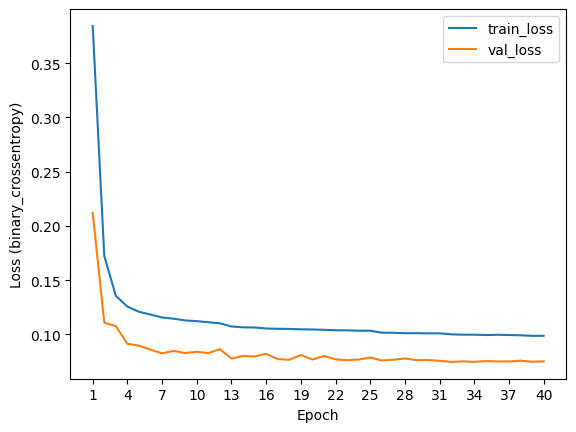

In [25]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = np.arange(1, len(loss) + 1)

plt.plot(epochs, loss, label='train_loss')
plt.plot(epochs, val_loss, label='val_loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss (binary_crossentropy)')
_ = plt.xticks(np.arange(1, len(loss) + 1, 3))

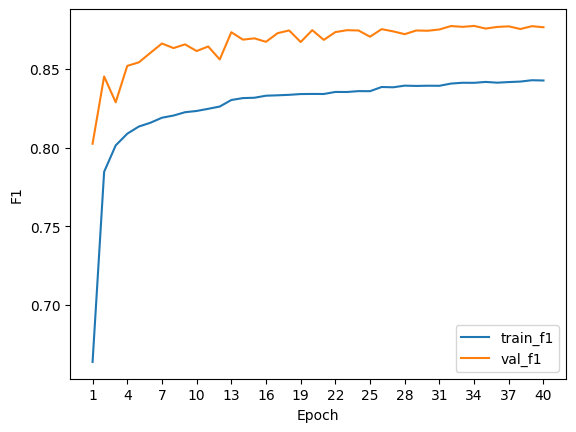

In [26]:
# REQUIREMENT: Run and display the output of this cell.
# REQUIREMENT: Do not change the code.
train_f1 = history.history['f1']
val_f1 = history.history['val_f1']

epochs = np.arange(1, len(train_f1) + 1)

plt.plot(epochs, train_f1, label='train_f1')
plt.plot(epochs, val_f1, label='val_f1')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('F1')
_ = plt.xticks(np.arange(1, len(loss) + 1, 3))